In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam

In [2]:
X, y = make_moons(100, noise=0.25,random_state=2)

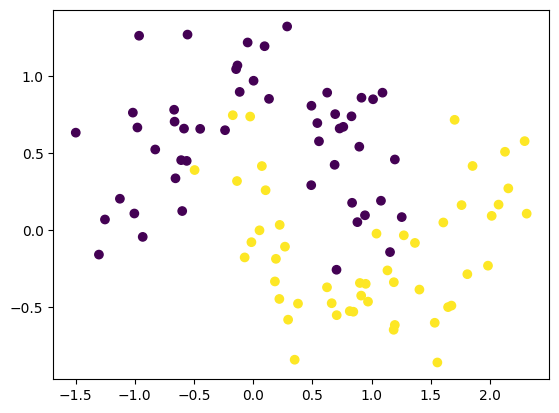

In [3]:
import matplotlib.pyplot as plt
plt.scatter(X[:,0], X[:,1], c=y)
plt.show()

In [4]:
model1 = Sequential()

model1.add(Dense(128,input_dim=2, activation="relu"))
model1.add(Dense(128, activation="relu"))
model1.add(Dense(1,activation='sigmoid'))

model1.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               384       
                                                                 
 dense_1 (Dense)             (None, 128)               16512     
                                                                 
 dense_2 (Dense)             (None, 1)                 129       
                                                                 
Total params: 17025 (66.50 KB)
Trainable params: 17025 (66.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [5]:
adam = Adam(learning_rate=0.01)
model1.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history = model1.fit(X, y, epochs=2000, validation_split = 0.2, verbose=2)

Epoch 1/2000


3/3 - 1s - loss: 0.6382 - accuracy: 0.5500 - val_loss: 0.3699 - val_accuracy: 0.9000 - 896ms/epoch - 299ms/step
Epoch 2/2000
3/3 - 0s - loss: 0.4601 - accuracy: 0.8000 - val_loss: 0.2309 - val_accuracy: 0.9000 - 28ms/epoch - 9ms/step
Epoch 3/2000
3/3 - 0s - loss: 0.3862 - accuracy: 0.8500 - val_loss: 0.2262 - val_accuracy: 0.9000 - 29ms/epoch - 10ms/step
Epoch 4/2000
3/3 - 0s - loss: 0.3629 - accuracy: 0.8500 - val_loss: 0.2338 - val_accuracy: 0.9000 - 30ms/epoch - 10ms/step
Epoch 5/2000
3/3 - 0s - loss: 0.3653 - accuracy: 0.8500 - val_loss: 0.2305 - val_accuracy: 0.9000 - 29ms/epoch - 10ms/step
Epoch 6/2000
3/3 - 0s - loss: 0.3524 - accuracy: 0.8500 - val_loss: 0.2277 - val_accuracy: 0.9000 - 28ms/epoch - 9ms/step
Epoch 7/2000
3/3 - 0s - loss: 0.3582 - accuracy: 0.8375 - val_loss: 0.2362 - val_accuracy: 0.9000 - 26ms/epoch - 9ms/step
Epoch 8/2000
3/3 - 0s - loss: 0.3449 - accuracy: 0.8500 - val_loss: 0.1893 - val_accuracy: 0.9000 - 28ms/epoch - 9ms/step
Epoch 9/2000
3/3

9600/9600 [==============================] - 7s 701us/step


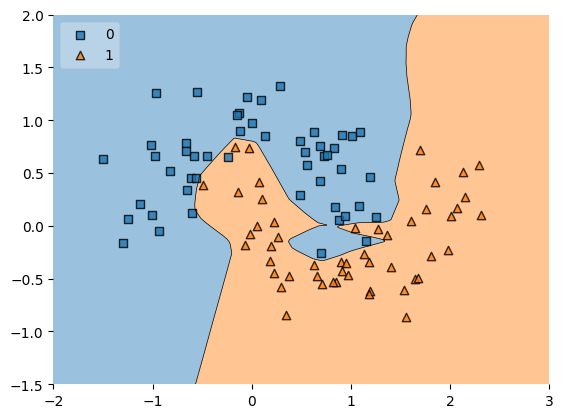

In [6]:
plot_decision_regions(X, y.astype('int'), clf=model1, legend=2)
plt.xlim(-2,3)
plt.ylim(-1.5,2)
plt.show()

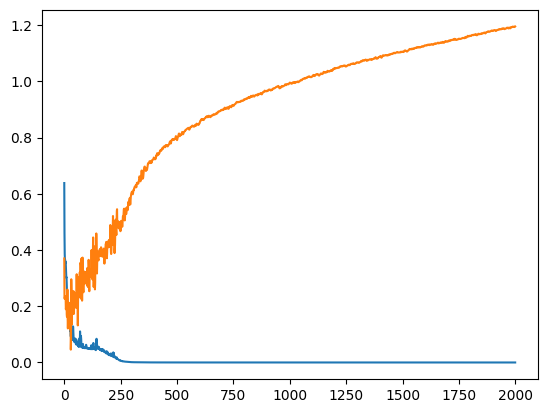

In [7]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

In [8]:
model2 = Sequential()

model2.add(Dense(128,input_dim=2, activation="relu",kernel_regularizer=tensorflow.keras.regularizers.l2(0.3)))
model2.add(Dense(128, activation="relu",kernel_regularizer=tensorflow.keras.regularizers.l2(0.03)))
model2.add(Dense(1,activation='sigmoid'))

model2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 128)               384       
                                                                 
 dense_4 (Dense)             (None, 128)               16512     
                                                                 
 dense_5 (Dense)             (None, 1)                 129       
                                                                 
Total params: 17025 (66.50 KB)
Trainable params: 17025 (66.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
adam = Adam(learning_rate=0.01)
model2.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history2 = model2.fit(X, y, epochs=2000, validation_split = 0.2, verbose=2)

Epoch 1/2000
3/3 - 1s - loss: 5.0498 - accuracy: 0.6375 - val_loss: 3.3870 - val_accuracy: 0.9000 - 607ms/epoch - 202ms/step
Epoch 2/2000
3/3 - 0s - loss: 2.9835 - accuracy: 0.7750 - val_loss: 1.9481 - val_accuracy: 0.9000 - 26ms/epoch - 9ms/step
Epoch 3/2000
3/3 - 0s - loss: 1.7380 - accuracy: 0.7875 - val_loss: 1.1563 - val_accuracy: 0.9000 - 25ms/epoch - 8ms/step
Epoch 4/2000
3/3 - 0s - loss: 1.0840 - accuracy: 0.8250 - val_loss: 0.8129 - val_accuracy: 0.9000 - 27ms/epoch - 9ms/step
Epoch 5/2000
3/3 - 0s - loss: 0.8151 - accuracy: 0.8125 - val_loss: 0.6921 - val_accuracy: 0.9000 - 27ms/epoch - 9ms/step
Epoch 6/2000
3/3 - 0s - loss: 0.7497 - accuracy: 0.8000 - val_loss: 0.7102 - val_accuracy: 0.8500 - 29ms/epoch - 10ms/step
Epoch 7/2000
3/3 - 0s - loss: 0.7722 - accuracy: 0.7250 - val_loss: 0.7032 - val_accuracy: 0.9000 - 28ms/epoch - 9ms/step
Epoch 8/2000
3/3 - 0s - loss: 0.7556 - accuracy: 0.7750 - val_loss: 0.6521 - val_accuracy: 0.9000 - 29ms/epoch - 10ms/step
Epoch 9/2000
3/3 - 

9600/9600 [==============================] - 8s 811us/step


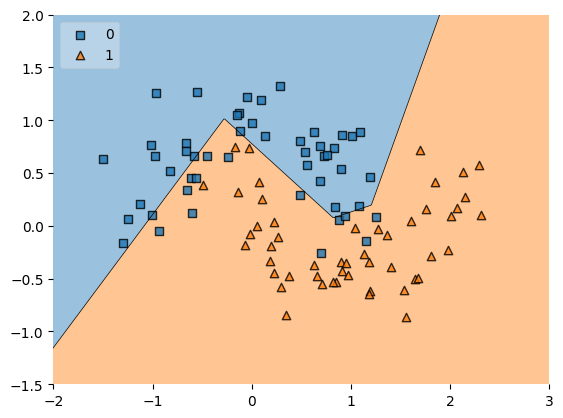

In [10]:
plot_decision_regions(X, y.astype('int'), clf=model2, legend=2)
plt.xlim(-2,3)
plt.ylim(-1.5,2)
plt.show()

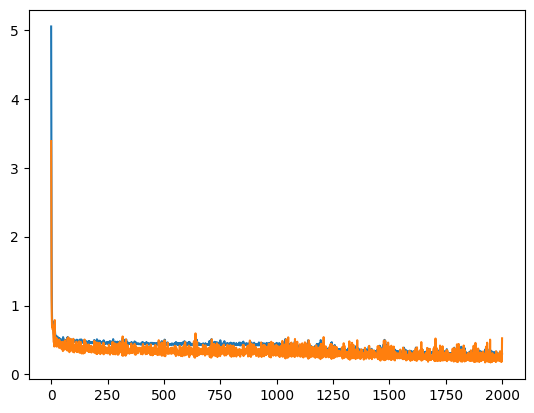

In [11]:
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])

In [12]:
model1_weight_layer1 = model1.get_weights()[0].reshape(256)
model2_weight_layer1 = model2.get_weights()[0].reshape(256)

<Axes: >

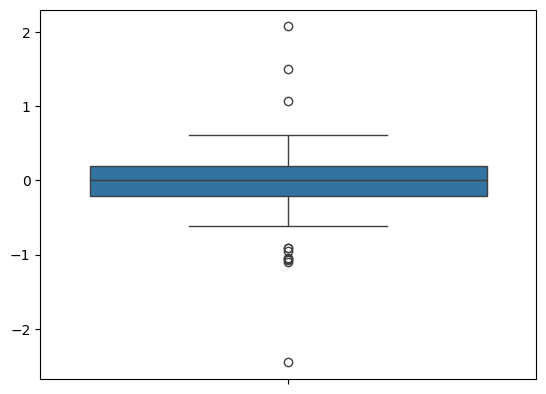

In [13]:
sns.boxplot(model1_weight_layer1)

<Axes: >

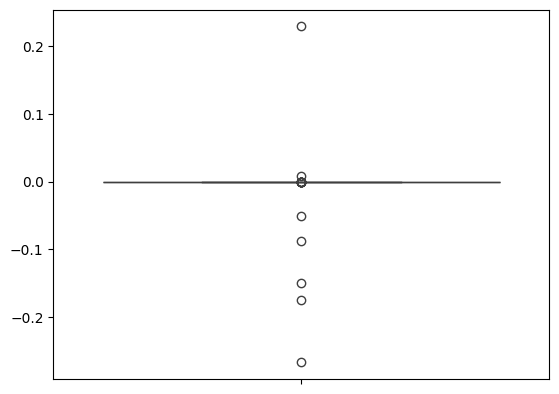

In [14]:
sns.boxplot(model2_weight_layer1)

In [15]:
model1_weight_layer1.min()

-2.4545045

In [16]:
model2_weight_layer1.min()

-0.26737732

C:\Users\arpan\AppData\Local\Temp\ipykernel_19952\2224180084.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(model1_weight_layer1)
C:\Users\arpan\AppData\Local\Temp\ipykernel_19952\2224180084.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(model2_weight_layer1)


<Axes: ylabel='Density'>

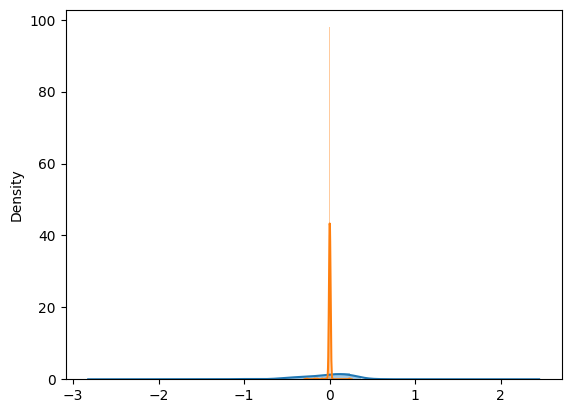

In [17]:
sns.distplot(model1_weight_layer1)
sns.distplot(model2_weight_layer1)

In [18]:
model1.get_weights()[0].reshape(256)

array([-3.25034708e-01,  1.83104321e-01, -3.80360074e-02, -1.26535371e-01,
        3.15039023e-03,  2.59032100e-01,  7.19941556e-02,  2.70670325e-01,
        3.15866470e-02,  1.94283977e-01,  3.14623527e-02, -3.54118854e-01,
       -3.35962623e-01,  2.37045363e-01, -3.91581684e-01,  3.52934361e-01,
        1.40023604e-01, -2.39995033e-01,  2.64298439e-01,  1.14358393e-02,
       -4.00581062e-01, -2.18437463e-01,  1.43380031e-01, -2.62689143e-01,
        2.03696355e-01,  1.66154101e-01, -3.03495914e-01, -7.31106028e-02,
       -1.74766779e-01,  2.63624191e-01, -4.29180376e-02,  9.16654691e-02,
        2.48135805e-01, -3.26791853e-01, -4.48734283e-01, -1.79519773e-01,
       -4.02438998e-01, -2.96901107e-01, -4.56876129e-01,  1.42202235e-03,
       -4.10524398e-01, -2.43554503e-01, -8.02846102e-04, -2.47456003e-02,
       -1.03688948e-02,  9.68713462e-02, -1.71163857e-01, -4.12285775e-01,
       -1.56685822e-02, -3.52389365e-01, -4.69310015e-01, -4.10827339e-01,
       -1.90615013e-01, -